# Detectors and photon statistics: responsivity, speed, noise, photon counting and the beam splitter with photons

Every optical measurement ends in a detector that turns photons into
electrons. How many electrons per watt, how fast, and with how much
noise decides what a camera, a fibre receiver, an infrared spectrometer
or a LiDAR can do. Earlier notebooks took the detector as given: notebook 120 (fibre link) used a PIN and an avalanche photodiode with a
responsivity and a noise formula, notebooks 18 (image processing) and 93
(the sensor) treated camera pixels, notebook 130 (time-of-flight LiDAR)
counted photons with SPADs and notebook 74 (coherence and stellar interferometry) correlated intensities after Hanbury Brown and Twiss. This
notebook asks where those numbers come from, and then looks at the photons
themselves:

1. responsivity from the quantum efficiency, and the band gap cutoffs of
   Si, InGaAs and HgCdTe,
2. absorption depth and the quantum efficiency of real photodiodes,
3. bandwidth against capacitance and transit time,
4. noise equivalent power and specific detectivity D*, the background
   limit of infrared detectors, and when a detector rather than the light
   sets the noise (the Fellgett advantage of notebook 111, Fourier transform spectroscopy),
5. photon counting with single-photon avalanche diodes and their dead
   time,
6. Poisson, super- and sub-Poissonian light,
7. the beam splitter with photons,
8. the Hong–Ou–Mandel dip.

The module `pyoptics.detectors` holds the functions, in SI units. The
receiver functions of `pyoptics.fibrecomm` and the excess noise of
`pyoptics.lidar` now come from it.

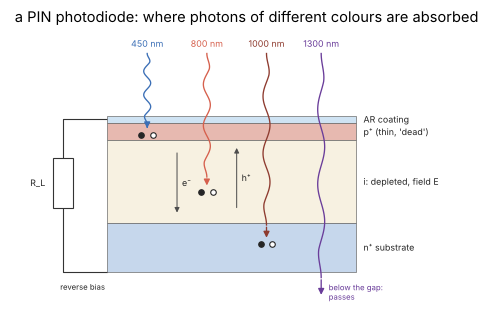

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import detectors as d
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

fig, ax = plt.subplots(figsize=(11, 4.6))
sketch.detector_layout(ax, "pin", title="a PIN photodiode: where photons of different colours are absorbed")
plt.show()

## 1. Responsivity and the band gap

A photon of energy $h\nu = hc/\lambda$ that is absorbed in the depleted
region of a photodiode makes one electron–hole pair, and the field there
sweeps both out into the circuit. If a fraction $\eta$ of the incident
photons does this (the quantum efficiency), the photocurrent per watt is

$$\mathcal{R} = \frac{\eta q}{h\nu} = \eta\,\frac{\lambda}{1239.84\ \mathrm{nm}}\ \mathrm{A/W}.$$

The responsivity therefore *grows* with the wavelength at constant
$\eta$: a watt of red light has more photons than a watt of blue light.
It ends abruptly where the photon energy falls below the band gap $E_g$,
at the cutoff $\lambda_c = hc/E_g$. Silicon (1.12 eV) stops near 1.1 µm,
In₀.₅₃Ga₀.₄₇As lattice matched to InP (0.74 eV) covers the telecom bands
up to 1.7 µm, and the alloy Hg₁₋ₓCdₓTe has a gap that goes from negative
(HgTe, a semimetal) to 1.6 eV (CdTe), so that its composition sets the
cutoff anywhere in the infrared. The gaps follow Varshni's
$E_g(T) = E_g(0) - aT^2/(T + b)$ for Si and InGaAs and the empirical
formula of Hansen, Schmit and Casselman for HgCdTe.

Si, 300 K                E_g = 1.125 eV, cutoff   1103 nm
InGaAs, 300 K            E_g = 0.735 eV, cutoff   1686 nm
HgCdTe x = 0.30, 77 K    E_g = 0.243 eV, cutoff   5101 nm
HgCdTe x = 0.21, 77 K    E_g = 0.099 eV, cutoff  12501 nm
Si at 77 K: E_g = 1.166 eV, cutoff 1063 nm


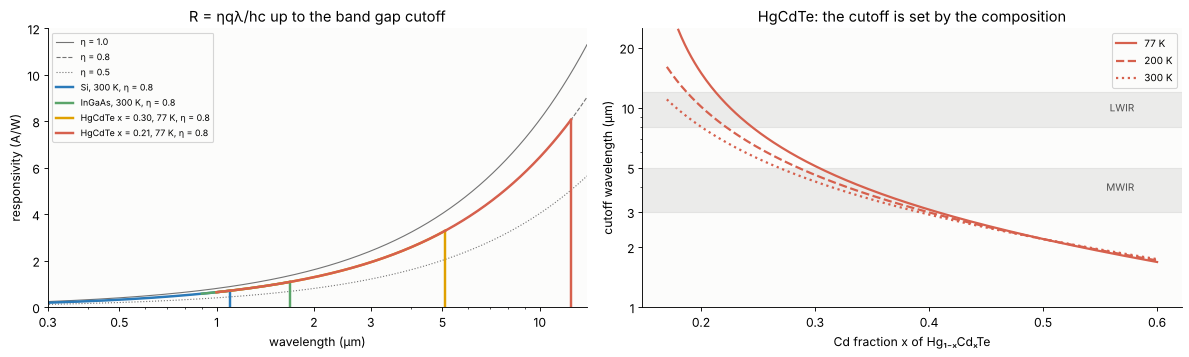

x = 0.20: cutoff 14.9 µm at 77 K, 8.0 µm at 300 K
x = 0.21: cutoff 12.5 µm at 77 K, 7.4 µm at 300 K
x = 0.30: cutoff 5.1 µm at 77 K, 4.3 µm at 300 K


In [2]:
gaps = [("Si, 300 K", d.bandgap("Si"), BLUE), ("InGaAs, 300 K", d.bandgap("InGaAs"), GREEN),
        ("HgCdTe x = 0.30, 77 K", d.bandgap("HgCdTe", 77, x=0.30), ORANGE),
        ("HgCdTe x = 0.21, 77 K", d.bandgap("HgCdTe", 77, x=0.21), RED)]
for name, Eg, _ in gaps:
    print("{:24s} E_g = {:.3f} eV, cutoff {:6.0f} nm".format(name, Eg, d.cutoff_wavelength(Eg)))
print("Si at 77 K: E_g = {:.3f} eV, cutoff {:.0f} nm".format(d.bandgap("Si", 77), d.cutoff_wavelength(d.bandgap("Si", 77))))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
lam = np.linspace(200, 14000, 2000)
for eta, ls in ((1.0, "-"), (0.8, "--"), (0.5, ":")):
    ax.plot(lam/1000, d.responsivity(lam, eta), color=GREY, ls=ls, lw=1, label=f"η = {eta}")
for (name, Eg, c), l0 in zip(gaps, (300, 900, 1000, 1000)):
    lc = d.cutoff_wavelength(Eg)
    l = np.linspace(l0, lc, 300)
    ax.plot(l/1000, d.responsivity(l, 0.8), color=c, lw=2.2, label=name + ", η = 0.8")
    ax.plot([lc/1000]*2, [0, d.responsivity(lc, 0.8)], color=c, lw=2.2)
ax.set_xscale("log"); ax.set_xlim(0.3, 14)
ax.set_xticks([0.3, 0.5, 1, 2, 3, 5, 10]); ax.set_xticklabels(["0.3", "0.5", "1", "2", "3", "5", "10"])
ax.set_ylim(0, 12)
ax.set_xlabel("wavelength (µm)"); ax.set_ylabel("responsivity (A/W)")
ax.set_title("R = ηqλ/hc up to the band gap cutoff"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
x = np.linspace(0.17, 0.6, 300)
for T, ls in ((77, "-"), (200, "--"), (300, ":")):
    Eg = d.hgcdte_bandgap(x, T)
    ok = Eg > 0.05
    ax.plot(x[ok], d.cutoff_wavelength(Eg[ok])/1000, color=RED, ls=ls, lw=2, label=f"{T} K")
for lo, hi, nm in ((3, 5, "MWIR"), (8, 12, "LWIR")):
    ax.axhspan(lo, hi, color=GREY, alpha=0.12)
    ax.text(0.58, (lo + hi)/2, nm, ha="right", va="center", fontsize=9, color="0.3")
ax.set_yscale("log"); ax.set_ylim(1, 25)
ax.set_yticks([1, 2, 3, 5, 10, 20]); ax.set_yticklabels(["1", "2", "3", "5", "10", "20"])
ax.set_xlabel("Cd fraction x of Hg₁₋ₓCdₓTe"); ax.set_ylabel("cutoff wavelength (µm)")
ax.set_title("HgCdTe: the cutoff is set by the composition"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
for xx in (0.2, 0.21, 0.3):
    print("x = {:.2f}: cutoff {:.1f} µm at 77 K, {:.1f} µm at 300 K".format(
        xx, d.cutoff_wavelength(d.hgcdte_bandgap(xx, 77))/1000, d.cutoff_wavelength(d.hgcdte_bandgap(xx, 300))/1000))

Silicon cuts off at 1103 nm (1063 nm when cooled to 77 K, since gaps grow
on cooling). For HgCdTe at 77 K, x = 0.30 gives the mid-wave infrared
(MWIR) window up to 5.1 µm and x = 0.21 the long-wave window up to
12.5 µm. The LWIR composition is touchy: x = 0.20 already reaches
14.9 µm, so a percent of cadmium shifts the cutoff by more than 2 µm, and
the same crystal warmed to 300 K would stop at 8 µm. HgCdTe's gap, unlike
that of most semiconductors, shrinks on cooling. The ideal responsivity
of an LWIR diode is close to 8 A/W, but it is useless unless it is cold,
as section 4 shows.

## 2. Absorption depth and quantum efficiency

Above the gap the light decays as $\exp(-\alpha z)$. The absorption
coefficient decides how thick the absorber must be. Silicon has an
*indirect* gap: a photon near the gap can only be absorbed with the help
of a phonon, and $\alpha$ climbs slowly over hundreds of nanometres (the
tabulated values of Green). InGaAs and HgCdTe have *direct* gaps, and
$\alpha$ jumps to 10⁴/cm within tens of meV of the edge
($\alpha \propto \sqrt{E - E_g}$ for InGaAs, the Kane region rule of Chu
et al. for HgCdTe, both with an exponential Urbach tail below the gap).

A photodiode collects the carriers made in its depleted layer of
thickness $d$ below a heavily doped surface layer $d_0$ in which they
recombine. With a reflectance $R_s$ of the surface,

$$\eta = (1 - R_s)\,e^{-\alpha d_0}\,(1 - e^{-\alpha d}).$$

The right panel uses $R_s$ = 3 % (an anti-reflection coating) and a dead
layer of 0.2 µm.

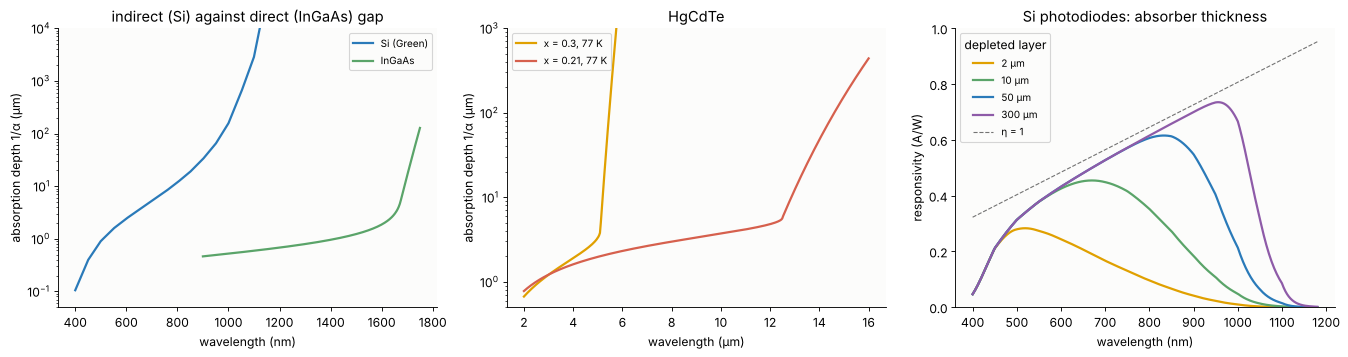

Si   450 nm: 1/alpha =     0.4 µm
Si   650 nm: 1/alpha =     3.6 µm
Si   850 nm: 1/alpha =    18.7 µm
Si   905 nm: 1/alpha =    34.9 µm
Si  1064 nm: 1/alpha =   943.8 µm
InGaAs 1310 nm: 1/alpha = 0.81 µm, 90 % absorbed in 1.86 µm
InGaAs 1550 nm: 1/alpha = 1.46 µm, 90 % absorbed in 3.36 µm
HgCdTe x = 0.21 at 10 µm: 1/alpha = 3.7 µm
Si 10 µm: eta(850, 905, 1064 nm) = [0.4  0.24 0.01]
Si 50 µm: eta(850, 905, 1064 nm) = [0.89 0.73 0.05]


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
l_si = np.linspace(400, 1180, 400)
ax.semilogy(l_si, d.absorption_depth("Si", l_si)*1E6, color=BLUE, lw=2, label="Si (Green)")
l_ig = np.linspace(900, 1750, 400)
ax.semilogy(l_ig, d.absorption_depth("InGaAs", l_ig)*1E6, color=GREEN, lw=2, label="InGaAs")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("absorption depth 1/α (µm)")
ax.set_ylim(0.05, 1E4); ax.legend(fontsize=9); ax.set_title("indirect (Si) against direct (InGaAs) gap")
ax = axes[1]
l_m = np.linspace(2000, 16000, 400)
for xx, c in ((0.30, ORANGE), (0.21, RED)):
    ax.semilogy(l_m/1000, d.absorption_depth("HgCdTe", l_m, 77, x=xx)*1E6, color=c, lw=2, label=f"x = {xx}, 77 K")
ax.set_xlabel("wavelength (µm)"); ax.set_ylabel("absorption depth 1/α (µm)")
ax.set_ylim(0.5, 1E3); ax.legend(fontsize=9); ax.set_title("HgCdTe")
ax = axes[2]
R_s, dead = 0.03, 0.2E-6
for th, c in ((2E-6, ORANGE), (10E-6, GREEN), (50E-6, BLUE), (300E-6, PURPLE)):
    eta = d.quantum_efficiency_layer(d.absorption_coefficient("Si", l_si), th, R_s, dead)
    ax.plot(l_si, d.responsivity(l_si, eta), color=c, lw=2, label=f"{th*1E6:.0f} µm")
ax.plot(l_si, d.responsivity(l_si, 1.0), color=GREY, ls="--", lw=1, label="η = 1")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("responsivity (A/W)")
ax.set_title("Si photodiodes: absorber thickness"); ax.legend(fontsize=9, title="depleted layer")
ax.set_ylim(0, 1.0)
plt.tight_layout(); plt.show()
for lam_x in (450, 650, 850, 905, 1064):
    print("Si {:5d} nm: 1/alpha = {:7.1f} µm".format(lam_x, d.absorption_depth("Si", lam_x)*1E6))
for lam_x in (1310, 1550):
    print("InGaAs {:d} nm: 1/alpha = {:.2f} µm, 90 % absorbed in {:.2f} µm".format(
        lam_x, d.absorption_depth("InGaAs", lam_x)*1E6, np.log(10)*d.absorption_depth("InGaAs", lam_x)*1E6))
print("HgCdTe x = 0.21 at 10 µm: 1/alpha = {:.1f} µm".format(d.absorption_depth("HgCdTe", 10000, 77, x=0.21)*1E6))
for th in (10E-6, 50E-6):
    eta = d.quantum_efficiency_layer(d.absorption_coefficient("Si", np.array([850, 905, 1064])), th, R_s, dead)
    print("Si {:.0f} µm: eta(850, 905, 1064 nm) = {}".format(th*1E6, np.round(eta, 2)))

The absorption depth in silicon goes from 0.4 µm in the blue to 19 µm at
850 nm, 35 µm at 905 nm and almost a millimetre at 1064 nm. A blue
photon is absorbed in the surface layer, so the dead layer costs blue
response; a near-infrared photon goes deep, so only a thick absorber
catches it. A 10 µm depleted layer has a quantum efficiency of 40 % at
850 nm, 24 % at 905 nm (the LiDAR wavelength of notebook 130, time-of-flight LiDAR) and 1 % at 1064 nm; 50 µm reach 89 %, 73 % and
5 %. The red peak of thick silicon diodes and the poor response of
cameras at 1064 nm both come from here. InGaAs absorbs 90 % of 1550 nm
light in 3.4 µm and HgCdTe 10 µm light within a few micrometres: direct
gap absorbers can be thin.

## 3. Bandwidth against capacitance

Two times limit how fast a photodiode answers. The junction is a plate
capacitor, $C = \varepsilon A/w$ with the depletion width $w$, which
charges through the load $R_L$: $f_{RC} = 1/(2\pi R_L C)$. And the
carriers need a time $w/v_s$ to cross the depleted layer at their
saturation velocity, which gives $f_{tr} \approx 0.44\,v_s/w$. A thin
layer crosses quickly but has a large capacitance and absorbs little; a
thick one is slow. With $1/f^2 = 1/f_{RC}^2 + 1/f_{tr}^2$ there is an
optimum width for each area.

diameter  20 µm: best w = 0.57 µm, f_3dB =  33.0 GHz, C = 68 fF, QE(1550) = 0.32
diameter  50 µm: best w = 1.42 µm, f_3dB =  13.2 GHz, C = 170 fF, QE(1550) = 0.62
diameter 100 µm: best w = 2.84 µm, f_3dB =   6.6 GHz, C = 341 fF, QE(1550) = 0.86
diameter 300 µm: best w = 8.53 µm, f_3dB =   2.2 GHz, C = 1020 fF, QE(1550) = 1.00


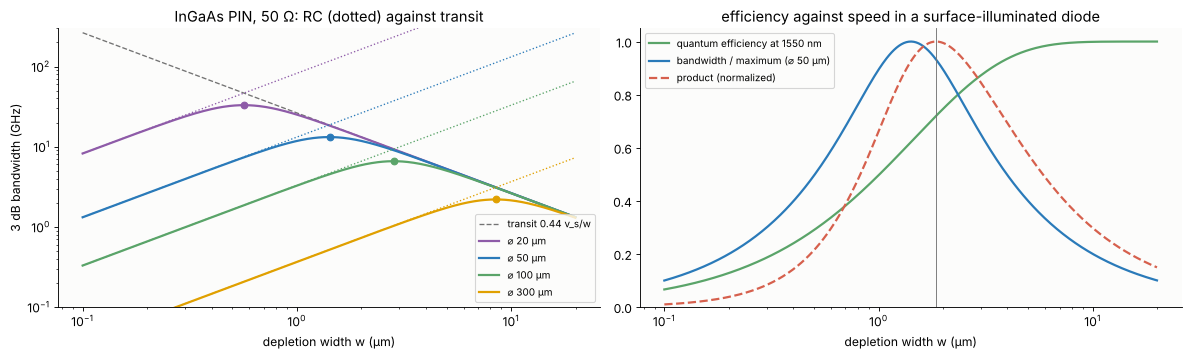

best efficiency-bandwidth product at w = 1.85 µm: QE 0.72, 12.3 GHz


In [4]:
w = np.logspace(-1, 1.3, 400)*1E-6
eps, vs = d.MATERIALS["InGaAs"]["eps_r"], d.MATERIALS["InGaAs"]["v_sat"]
alpha1550 = d.absorption_coefficient("InGaAs", 1550)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
ax.loglog(w*1E6, d.transit_bandwidth(w, vs)/1E9, color=GREY, ls="--", lw=1.2, label="transit 0.44 v_s/w")
for D_um, c in ((20, PURPLE), (50, BLUE), (100, GREEN), (300, ORANGE)):
    A = np.pi*(D_um*1E-6/2)**2
    ax.loglog(w*1E6, d.rc_bandwidth(d.junction_capacitance(A, w, eps))/1E9, color=c, ls=":", lw=1.2)
    f = d.photodiode_bandwidth(A, w, eps_r=eps, v_sat=vs)
    i = np.argmax(f)
    ax.loglog(w*1E6, f/1E9, color=c, lw=2, label=f"⌀ {D_um} µm")
    ax.plot(w[i]*1E6, f[i]/1E9, "o", color=c)
    print("diameter {:3d} µm: best w = {:.2f} µm, f_3dB = {:5.1f} GHz, C = {:.0f} fF, QE(1550) = {:.2f}".format(
        D_um, w[i]*1E6, f[i]/1E9, d.junction_capacitance(A, w[i], eps)*1E15,
        d.quantum_efficiency_layer(alpha1550, w[i])))
ax.set_ylim(0.1, 300)
ax.set_xlabel("depletion width w (µm)"); ax.set_ylabel("3 dB bandwidth (GHz)")
ax.set_title("InGaAs PIN, 50 Ω: RC (dotted) against transit"); ax.legend(fontsize=9)
ax = axes[1]
A = np.pi*(25E-6)**2
f = d.photodiode_bandwidth(A, w, eps_r=eps, v_sat=vs)
eta = d.quantum_efficiency_layer(alpha1550, w)
ax.semilogx(w*1E6, eta, color=GREEN, lw=2, label="quantum efficiency at 1550 nm")
ax.semilogx(w*1E6, f/f.max(), color=BLUE, lw=2, label="bandwidth / maximum (⌀ 50 µm)")
ax.semilogx(w*1E6, eta*f/np.max(eta*f), color=RED, lw=2, ls="--", label="product (normalized)")
i = np.argmax(eta*f)
ax.axvline(w[i]*1E6, color=GREY, lw=0.8)
ax.set_xlabel("depletion width w (µm)"); ax.set_ylim(0, 1.05)
ax.set_title("efficiency against speed in a surface-illuminated diode"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print("best efficiency-bandwidth product at w = {:.2f} µm: QE {:.2f}, {:.1f} GHz".format(w[i]*1E6, eta[i], f[i]/1E9))

The optimum moves to thinner layers for smaller diodes: a 50 µm InGaAs
diode on 50 Ω peaks at 13 GHz with a 1.4 µm layer and 170 fF; the same
diode 20 µm across reaches 33 GHz but absorbs only a third of the light,
and one 300 µm across manages 2.2 GHz. The efficiency–bandwidth product
of a surface-illuminated diode is limited (right): the best compromise
for a 50 µm diode is 1.9 µm, 72 % and 12 GHz. Receivers for 25 Gb/s and
beyond therefore illuminate the absorber from the side, in a waveguide,
where the light travels along the layer and the absorption length no
longer equals the transit length.

## 4. Noise, NEP and D*

The receiver of notebook 120 (fibre link) has shot noise
$i_s^2 = 2qM^2F(M)(\mathcal R P + I_d)B$ and thermal noise
$i_T^2 = 4k_BTF_nB/R_L$ in the bandwidth $B$. To compare detectors one
refers the noise to the input. The **noise equivalent power** is the
optical power whose signal equals the noise in 1 Hz,
$\mathrm{NEP} = i_n/\mathcal R$ in W/√Hz; for a photodiode in the dark
$i_n^2 = 2qI_d + 4k_BT/R_{sh}$, the dark current shot noise and the
Johnson noise of the shunt resistance. Since the noise of most detectors
grows with the square root of their area, the **specific detectivity**
$D^* = \sqrt{A}/\mathrm{NEP}$ (in Jones, cm √Hz/W) is a property of the
material and its technology rather than of the size.

An infrared detector looks at a warm world. Its own photons, from the
300 K surroundings that it sees within its field of view, have a shot
noise of their own. A detector whose noise is this background is
*background limited* (BLIP), with

$$D^*_\mathrm{BLIP} = \frac{\lambda_c}{hc}\sqrt{\frac{\eta}{2\Phi_B}}$$

for the photon flux density $\Phi_B$ of the background below the cutoff
(a photoconductor has $\sqrt 2$ less). A cold shield that narrows the
field of view to the half angle $\theta$ reduces $\Phi_B$ by
$\sin^2\theta$. A cooled photodiode at zero bias has the Johnson limited
$D^* = \mathcal R\sqrt{R_0A/(4k_BT)}$ with its resistance–area product
$R_0A$.

The right panel asks the question behind the Fellgett (multiplex)
advantage of notebook 111 (Fourier transform spectroscopy): at which power
does the photon noise of the signal itself, $\sqrt{2q\mathcal R P}$,
overtake the detector noise $\mathrm{NEP}\cdot\mathcal R$? The crossover
is $P_\times = \mathrm{NEP}^2\mathcal R/(2q)$.

Si PIN, 900 nm                         D* = 2.0e+13 Jones alone, 2.0e+13 Jones with a 300 K scene through a 30° cold shield
InGaAs PIN, 1550 nm                    D* = 4.5e+12 Jones alone, 4.5e+12 Jones with a 300 K scene through a 30° cold shield
HgCdTe MWIR, 77 K, R₀A = 1E6 Ω cm²     D* = 4.2e+13 Jones alone, 3.0e+11 Jones with a 300 K scene through a 30° cold shield
HgCdTe LWIR, 77 K, R₀A = 100 Ω cm²     D* = 9.1e+11 Jones alone, 9.6e+10 Jones with a 300 K scene through a 30° cold shield
BLIP at 5 and 10.5 µm (hemisphere): 1.5e+11, 5.0e+10 Jones
BLIP at 10.5 µm with a 30° cold shield: 9.9e+10 Jones
DTGS, ⌀ 2 mm, 10 µm          NEP = 8.9e-10 W/√Hz, photon noise takes over above 2.0e+01 W
HgCdTe LWIR, 1 mm², 10 µm    NEP = 3.3e-12 W/√Hz, photon noise takes over above 2.0e-04 W
Si PIN, 1 mm², 600 nm        NEP = 8.1e-15 W/√Hz, photon noise takes over above 7.8e-11 W


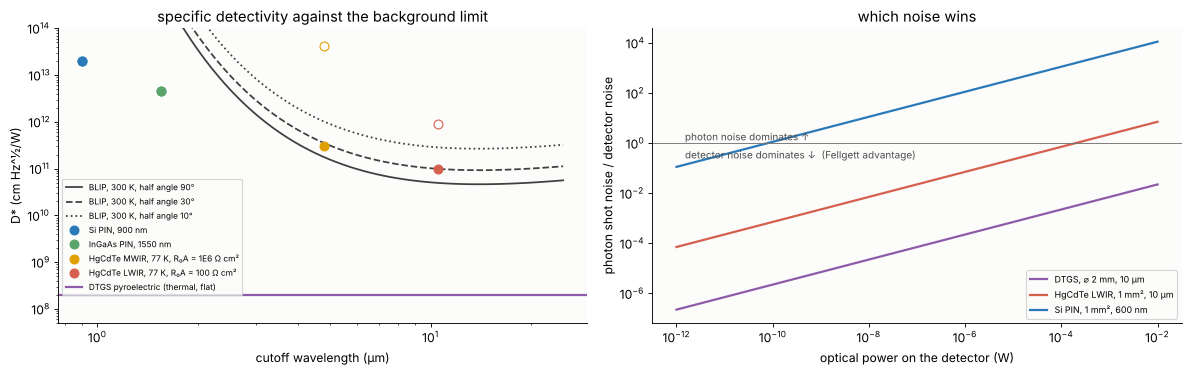

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
lc = np.logspace(np.log10(1500), np.log10(25000), 60)
for ha, ls in ((90, "-"), (30, "--"), (10, ":")):
    ax.loglog(lc/1000, d.blip_detectivity(lc, 300, np.radians(ha)), color="0.25", ls=ls, lw=1.6,
              label=f"BLIP, 300 K, half angle {ha}°")
# real detectors (area 1 mm² unless noted)
dets = []
A_mm2 = 1E-6
nep_si = d.nep(d.responsivity(900, 0.85), dark_current=20E-12, shunt_ohm=5E9)
dets.append(("Si PIN, 900 nm", 900, d.specific_detectivity(nep_si, A_mm2), BLUE))
nep_ig = d.nep(d.responsivity(1550, 0.8), dark_current=1E-9, shunt_ohm=100E6)
dets.append(("InGaAs PIN, 1550 nm", 1550, d.specific_detectivity(nep_ig, A_mm2), GREEN))
R_mw = d.responsivity(4800, 0.7)
dets.append(("HgCdTe MWIR, 77 K, R₀A = 1E6 Ω cm²", 4800, d.r0a_detectivity(R_mw, 1E6, 77), ORANGE))
R_lw = d.responsivity(10500, 0.7)
dets.append(("HgCdTe LWIR, 77 K, R₀A = 100 Ω cm²", 10500, d.r0a_detectivity(R_lw, 100, 77), RED))
for nm, l, D, c in dets:
    D_bg = d.blip_detectivity(l*1.05, 300, np.radians(30))
    D_tot = 1/np.sqrt(1/D**2 + 1/D_bg**2)
    ax.plot(l/1000, D, "o", mfc="white", mec=c, ms=8)
    ax.plot(l/1000, D_tot, "o", color=c, ms=8, label=nm)
    print("{:38s} D* = {:.1e} Jones alone, {:.1e} Jones with a 300 K scene through a 30° cold shield".format(nm, D, D_tot))
ax.axhline(2E8, color=PURPLE, lw=2, label="DTGS pyroelectric (thermal, flat)")
ax.set_xlabel("cutoff wavelength (µm)"); ax.set_ylabel("D* (cm Hz^½/W)")
ax.set_ylim(5E7, 1E14); ax.legend(fontsize=7.5, loc="lower left", bbox_to_anchor=(0.0, 0.08))
ax.set_title("specific detectivity against the background limit")
print("BLIP at 5 and 10.5 µm (hemisphere): {:.1e}, {:.1e} Jones".format(d.blip_detectivity(5000), d.blip_detectivity(10500)))
print("BLIP at 10.5 µm with a 30° cold shield: {:.1e} Jones".format(d.blip_detectivity(10500, half_angle=np.radians(30))))
# Fellgett: when is the detector the dominant noise?
ax = axes[1]
P = np.logspace(-12, -2, 300)
cases = (("DTGS, ⌀ 2 mm, 10 µm", 2E8, np.pi*(1E-3)**2, 10000, 1.0, PURPLE),
         ("HgCdTe LWIR, 1 mm², 10 µm", 3E10, 1E-6, 10000, 0.7, RED),
         ("Si PIN, 1 mm², 600 nm", d.specific_detectivity(d.nep(d.responsivity(600, 0.8), 20E-12, 5E9), 1E-6),
          1E-6, 600, 0.8, BLUE))
for nm, D, A, l, eta, c in cases:
    nep = d.nep_from_detectivity(D, A)
    R = d.responsivity(l, eta)
    shot = np.sqrt(2*d.Q_E*R*P)/R
    ax.loglog(P, shot/nep, color=c, lw=2, label=nm)
    Px = nep**2*R/(2*d.Q_E)
    print("{:28s} NEP = {:.1e} W/√Hz, photon noise takes over above {:.1e} W".format(nm, nep, Px))
ax.axhline(1, color=GREY, lw=0.8)
ax.text(1.5E-12, 1.3, "photon noise dominates ↑", fontsize=9, color="0.3")
ax.text(1.5E-12, 0.6, "detector noise dominates ↓  (Fellgett advantage)", fontsize=9, color="0.3", va="top")
ax.set_xlabel("optical power on the detector (W)"); ax.set_ylabel("photon shot noise / detector noise")
ax.set_title("which noise wins"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

Visible and near-infrared photodiodes beat the background limit by
orders of magnitude (2×10¹³ Jones for the Si diode, 4.5×10¹² for
InGaAs), because a room-temperature world sends almost no photons below
1.7 µm. In the infrared the background wins: the BLIP limit of a 300 K
hemisphere is 1.5×10¹¹ Jones at 5 µm and 5×10¹⁰ at 10.5 µm, and a 30°
cold shield doubles the latter. The MWIR diode with R₀A = 10⁶ Ω cm² is a
hundred times quieter by itself (open circle) than its background lets
it be (filled circle): it is background limited, as a good infrared
camera should be. The LWIR diode with R₀A = 100 Ω cm² is close to the
limit. The pyroelectric DTGS detector of a laboratory FTIR, a thermal
detector with a flat response, sits at 2×10⁸ Jones.

That ordering is the Fellgett advantage in numbers. The photon noise of
the light would overtake the noise of the DTGS detector only at 20 W,
and that of the cooled HgCdTe diode at 0.2 mW. Every infrared
spectrometer is therefore detector limited, and measuring all spectral
elements at once (the FTS) gains √M. A silicon photodiode at 600 nm is
shot noise limited above 80 pW; with visible light the multiplex
advantage is gone, as the Monte Carlo of notebook 111 (Fourier transform spectroscopy) showed.

## 5. Photon counting with SPADs

A single-photon avalanche diode (SPAD) is biased above its breakdown
voltage. One photoelectron starts an avalanche that grows to milliamps,
a digital click with picosecond timing. The diode cannot tell one photon
from ten: for Poisson light with $\bar n$ photons in a gate, the click
probability is $1 - \exp(-\eta\bar n - n_d)$ with the photon detection
efficiency $\eta$ and the dark counts $n_d$ per gate. Afterwards the
avalanche must be quenched and the bias restored: during this **dead
time** $\tau$ the detector is blind. If only detections restart the dead
time (active quenching, non-paralyzable), the measured rate is
$r/(1 + r\tau)$ and saturates at $1/\tau$; if every photon restarts it
(a passively quenched diode, paralyzable), it is $r\,e^{-r\tau}$ and goes
back to zero at high light levels. The simulation below sends Poisson
photons through `spad_detections()` with a 22 ns dead time.

1E7/s true: 8.197e+06/s measured (non-paralyzable), corrected back to 1.000e+07/s
1E7/s true: 8.025e+06/s measured (paralyzable), corrected back to 1.000e+07/s; maximum 1.67e+07/s at r = 1/tau


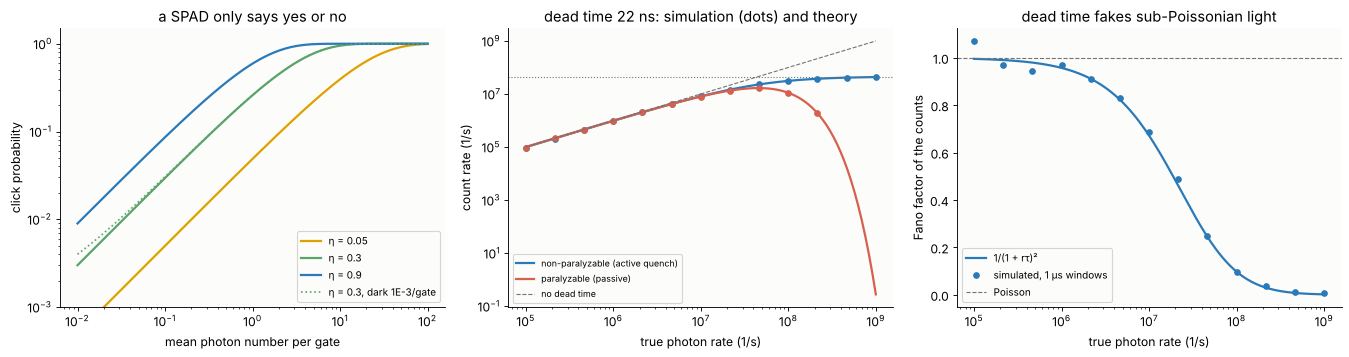

ideal photon counter, BER 1E-9: 10.0 photons per bit on average


In [6]:
rng = np.random.default_rng(11)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
n = np.logspace(-2, 2, 200)
for eta, c in ((0.05, ORANGE), (0.3, GREEN), (0.9, BLUE)):
    ax.loglog(n, d.click_probability(n, eta), color=c, lw=2, label=f"η = {eta}")
ax.loglog(n, d.click_probability(n, 0.3, dark=1E-3), color=GREEN, ls=":", lw=1.5, label="η = 0.3, dark 1E-3/gate")
ax.set_xlabel("mean photon number per gate"); ax.set_ylabel("click probability")
ax.set_ylim(1E-3, 1.5); ax.legend(fontsize=9); ax.set_title("a SPAD only says yes or no")
ax = axes[1]
tau = 22E-9
r_true = np.logspace(5, 9, 13)
dur = 2E-3
for par, c, nm in ((False, BLUE, "non-paralyzable (active quench)"), (True, RED, "paralyzable (passive)")):
    meas = []
    r_sim = r_true[r_true < 4E8] if par else r_true
    for r in r_sim:
        t = d.poisson_arrivals(r, min(dur, 2E5/r), rng)
        meas.append(len(d.spad_detections(t, tau, par))/min(dur, 2E5/r))
    rr = np.logspace(5, 9, 200)
    ax.loglog(rr, d.dead_time_rate(rr, tau, par), color=c, lw=2, label=nm)
    ax.loglog(r_sim, meas, "o", color=c, ms=5)
ax.loglog(rr, rr, color=GREY, ls="--", lw=1, label="no dead time")
ax.axhline(1/tau, color=GREY, ls=":", lw=1)
ax.set_xlabel("true photon rate (1/s)"); ax.set_ylabel("count rate (1/s)")
ax.set_title(f"dead time {tau*1E9:.0f} ns: simulation (dots) and theory"); ax.legend(fontsize=8)
m = d.dead_time_rate(1E7, tau)
print("1E7/s true: {:.3e}/s measured (non-paralyzable), corrected back to {:.3e}/s".format(m, d.true_rate(m, tau)))
m = d.dead_time_rate(1E7, tau, True)
print("1E7/s true: {:.3e}/s measured (paralyzable), corrected back to {:.3e}/s; maximum {:.2e}/s at r = 1/tau".format(
    m, d.true_rate(m, tau, True), 1/(np.e*tau)))
ax = axes[2]
fano_sim = []
for r in r_true:
    t = d.poisson_arrivals(r, 2E-3, rng) if r < 2E8 else d.poisson_arrivals(r, 2E-4, rng)
    det = d.spad_detections(t, tau)
    T = t[-1]
    counts = np.histogram(det, bins=int(T/1E-6), range=(0, int(T/1E-6)*1E-6))[0]
    fano_sim.append(np.var(counts)/np.mean(counts))
ax.semilogx(rr, d.dead_time_fano(rr, tau), color=BLUE, lw=2, label="1/(1 + rτ)²")
ax.semilogx(r_true, fano_sim, "o", color=BLUE, ms=5, label="simulated, 1 µs windows")
ax.axhline(1, color=GREY, ls="--", lw=1, label="Poisson")
ax.set_xlabel("true photon rate (1/s)"); ax.set_ylabel("Fano factor of the counts")
ax.set_title("dead time fakes sub-Poissonian light"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print("ideal photon counter, BER 1E-9: {:.1f} photons per bit on average".format(d.quantum_limit_photons(1E-9)))

At a true rate of 10⁷/s the dead time already loses 18 % (non-paralyzable)
or 20 % (paralyzable) of the photons; both are corrected exactly by
`true_rate()` as long as the light is Poissonian. A paralyzable detector
counts at most $1/(e\tau)$ = 1.7×10⁷/s, and the same count rate belongs to
two light levels, a trap in bright light. The pile-up of LiDAR histograms
in notebook 130 (time-of-flight LiDAR) is the same effect within one
laser period.

The right panel is a warning for the next section. A dead time removes
the photons that come too close to the last one, so the clicks are more
regular than the photons: the counts in a window long against $\tau$
have the Fano factor $1/(1 + r\tau)^2 < 1$. A detector near saturation
makes Poisson light look sub-Poissonian.

The quantum limit of a digital receiver also follows from photon
counting: with an ideal counter, a one is mistaken for a zero only when
it brings no photon, $e^{-N_1}/2 = \mathrm{BER}$, which needs 10 photons
per bit on average at 10⁻⁹. The receivers of notebook 120 (fibre link)
need a few hundred to a few thousand.

## 6. Poisson, super- and sub-Poissonian light

Count photons in a window and repeat. The counts $n$ have a mean
$\langle n\rangle$, a variance $(\Delta n)^2$, Mandel's
$Q = (\Delta n)^2/\langle n\rangle - 1$ and the normalized second factorial
moment $g^{(2)} = \langle n(n-1)\rangle/\langle n\rangle^2 = 1 + Q/\langle n\rangle$.

- A laser far above threshold emits a coherent state: **Poisson**
  statistics, $Q = 0$, $g^{(2)} = 1$.
- A single mode of thermal light (a window short against its coherence
  time) has the **Bose–Einstein** distribution
  $\langle n\rangle^n/(1 + \langle n\rangle)^{n+1}$: $Q = \langle n\rangle$,
  $g^{(2)} = 2$; $M$ modes give the negative binomial distribution with
  $g^{(2)} = 1 + 1/M$. **Super-Poissonian.**
- A number state $|N\rangle$ has no fluctuations at all, $Q = -1$,
  $g^{(2)} = 1 - 1/N$. **Sub-Poissonian**, impossible for any classical
  intensity, since a classical $I(t)$ always gives
  $(\Delta n)^2 = \langle n\rangle + \langle n\rangle^2\mathrm{var}(I)/\langle I\rangle^2 \ge \langle n\rangle$.

A loss of transmission $\eta$ (or a detector of efficiency $\eta$)
removes each photon independently. This binomial thinning keeps Poisson
light Poissonian and multiplies $Q$ by $\eta$.

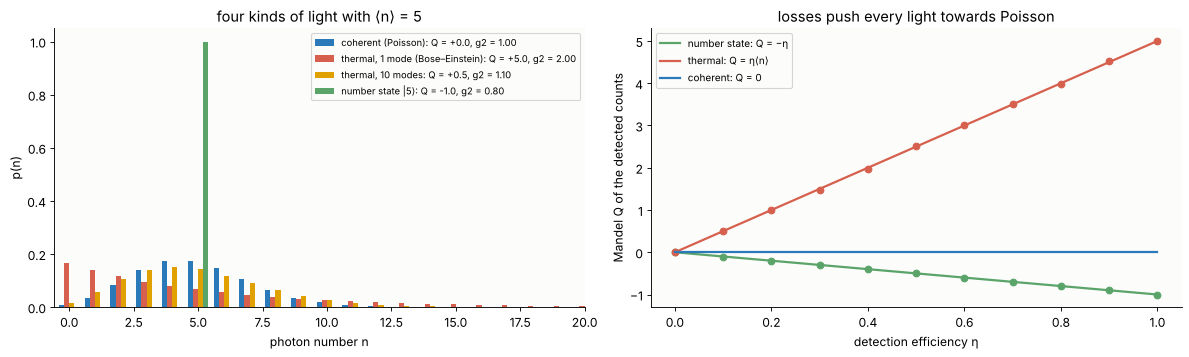

In [7]:
nbar = 5.0
k = np.arange(0, 400)
dists = (("coherent (Poisson)", d.poisson_pmf(k, nbar), BLUE),
         ("thermal, 1 mode (Bose–Einstein)", d.thermal_pmf(k, nbar), RED),
         ("thermal, 10 modes", d.thermal_pmf(k, nbar, 10), ORANGE),
         ("number state |5⟩", d.fock_pmf(k, 5), GREEN))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
wdt = 0.2
for i, (nm, p, c) in enumerate(dists):
    m, var, Q, g = d.pmf_moments(k, p)
    ax.bar(k[:21] + (i - 1.5)*wdt, p[:21], wdt, color=c, label=f"{nm}: Q = {Q:+.1f}, g2 = {g:.2f}")
ax.set_xlabel("photon number n"); ax.set_ylabel("p(n)"); ax.set_xlim(-0.6, 20)
ax.set_title("four kinds of light with ⟨n⟩ = 5"); ax.legend(fontsize=8.5)
ax = axes[1]
eta = np.linspace(0, 1, 11)
N = 5
q_sim = [d.mandel_q(d.thin(np.full(200000, N), e, rng)) if e > 0 else 0 for e in eta]
ax.plot(eta, -eta, color=GREEN, lw=2, label="number state: Q = −η")
ax.plot(eta, q_sim, "o", color=GREEN)
q_th = [d.mandel_q(d.thin(rng.geometric(1/(1 + N), 200000) - 1, e, rng)) if e > 0 else 0 for e in eta]
ax.plot(eta, eta*N, color=RED, lw=2, label="thermal: Q = η⟨n⟩")
ax.plot(eta, q_th, "o", color=RED)
ax.plot(eta, 0*eta, color=BLUE, lw=2, label="coherent: Q = 0")
ax.set_xlabel("detection efficiency η"); ax.set_ylabel("Mandel Q of the detected counts")
ax.set_title("losses push every light towards Poisson"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Losses push every kind of light towards Poisson: a number state seen
through 50 % efficiency has only $Q = -0.5$, which is why sub-Poissonian
light needs efficient detectors and low losses, and why it is so rarely
seen. Thermal light keeps a positive $Q$ but loses it in proportion.

**Chaotic light in time.** Thermal light is a field made of many
independent emitters: a complex Gaussian random process whose intensity
fluctuates on the scale of its coherence time $\tau_c$, exponentially
distributed at each instant like the speckle of notebook 87 (speckle reduction) in space. `chaotic_intensity()` makes such a field with a
Gaussian spectrum, and `photon_counts()` draws Poisson counts with this
fluctuating rate (Mandel's semiclassical photodetection). Counted in
windows $T$, $Q$ is $\langle n\rangle$ for $T \ll \tau_c$ (one mode) and
$\langle n\rangle\tau_c/T$ for $T \gg \tau_c$ (many modes averaged).

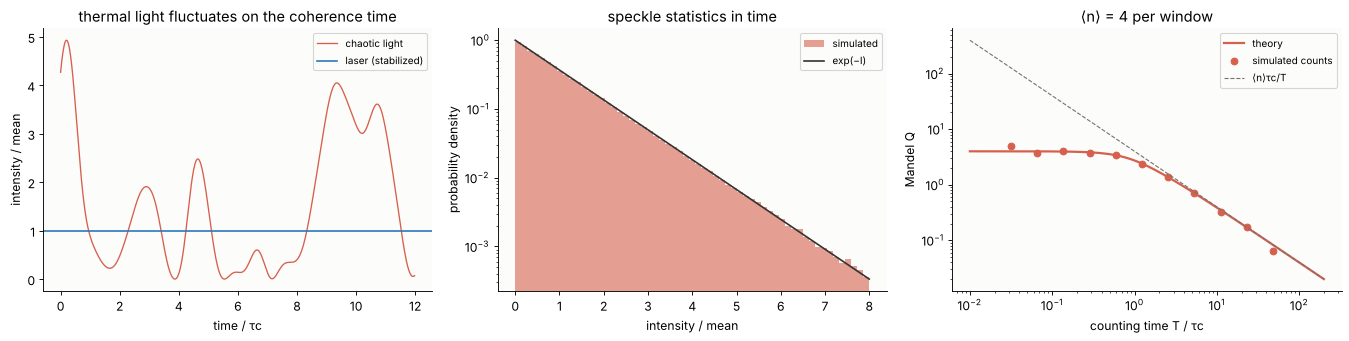

sunlight, 1 nm filter at 550 nm: tau_c = 1.01 ps


In [8]:
tau_c, dt = 1.0, 0.02
I = d.chaotic_intensity(2**21, dt, tau_c, rng=7)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]
tt = np.arange(600)*dt
ax.plot(tt, I[:600], color=RED, lw=1.2, label="chaotic light")
ax.axhline(1, color=BLUE, lw=1.5, label="laser (stabilized)")
ax.set_xlabel("time / τc"); ax.set_ylabel("intensity / mean"); ax.legend(fontsize=9)
ax.set_title("thermal light fluctuates on the coherence time")
ax = axes[1]
bins = np.linspace(0, 8, 60)
ax.hist(I, bins=bins, density=True, color=RED, alpha=0.6, label="simulated")
ax.plot(bins, np.exp(-bins), color="0.2", lw=1.5, label="exp(−I)")
ax.set_yscale("log"); ax.set_xlabel("intensity / mean"); ax.set_ylabel("probability density")
ax.set_title("speckle statistics in time"); ax.legend(fontsize=9)
ax = axes[2]
Ts = np.logspace(-1.5, 2, 12)
mean_counts = 4.0
q_sim = [d.mandel_q(d.photon_counts(I, dt, mean_counts/T, T, rng)) for T in Ts]
TT = np.logspace(-2, 2.3, 200)
ax.loglog(TT, d.mandel_q_chaotic(mean_counts, TT, tau_c), color=RED, lw=2, label="theory")
ax.loglog(Ts, q_sim, "o", color=RED, label="simulated counts")
ax.loglog(TT, mean_counts/TT, color=GREY, ls="--", lw=1, label="⟨n⟩τc/T")
ax.set_xlabel("counting time T / τc"); ax.set_ylabel("Mandel Q")
ax.set_title(f"⟨n⟩ = {mean_counts:.0f} per window"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print("sunlight, 1 nm filter at 550 nm: tau_c = {:.2f} ps".format((550E-9)**2/(3E8*1E-9)*1E12))

The simulated counts follow the closed form over four decades of the
counting time. For real thermal sources the excess noise is tiny: sunlight
through a 1 nm filter has $\tau_c \approx$ 1 ps, so any electronic
counting window averages over millions of modes, and $Q$ is reduced by
the same factor. Hanbury Brown and Twiss had to correlate fast
photocurrents of large telescopes to see it (notebook 74, coherence and stellar interferometry).

## 7. The beam splitter with photons

A lossless beam splitter with transmittance $T$ and reflectance
$R = 1 - T$ acts on the photon creation operators of its two inputs,
$\hat a_1^\dagger \to t\hat b_1^\dagger + r\hat b_2^\dagger$,
$\hat a_2^\dagger \to r\hat b_1^\dagger + t\hat b_2^\dagger$ with
$t = \sqrt T$, $r = i\sqrt R$ (the phase $i$ makes it unitary).
`beam_splitter_fock()` expands $(\hat a_1^\dagger)^{n_1}(\hat a_2^\dagger)^{n_2}|0\rangle$
and returns the probabilities of $k$ photons at output 3 and $N - k$ at
output 4.

With vacuum at the second input every light is split binomially, each
photon independently. The **Hanbury Brown–Twiss** experiment therefore
measures the $g^{(2)}$ of the input: the normalized coincidences
$\langle n_3 n_4\rangle/(\langle n_3\rangle\langle n_4\rangle)$ of the two
outputs are $\langle n(n-1)\rangle/\langle n\rangle^2$. The simulation sends
2 million pulses of laser light ($\bar n$ = 0.5), thermal light
($\bar n$ = 0.5) and single photons onto a 50:50 splitter followed by two
detectors of 20 % efficiency (the efficiency cancels in the ratio).

laser (coherent)         g2 from HBT coincidences 0.998, g2 of the input 1.002, coincidences per pulse 2.37e-03
thermal                  g2 from HBT coincidences 2.030, g2 of the input 2.005, coincidences per pulse 4.37e-03


single photons, η = 0.2  g2 from HBT coincidences 0.000, g2 of the input 0.000, coincidences per pulse 0.00e+00


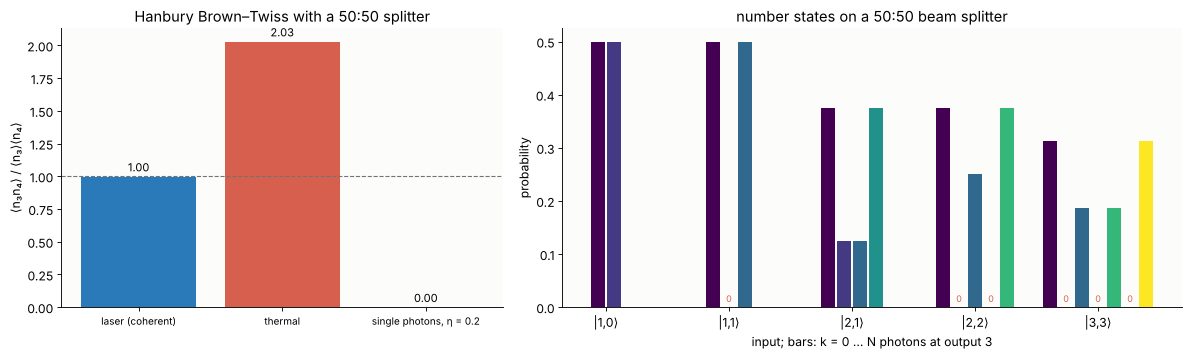

|1,0> -> [0.5 0.5]
|1,1> -> [0.5 0.  0.5]
|2,1> -> [0.375 0.125 0.125 0.375]
|2,2> -> [0.375 0.    0.25  0.    0.375]
|3,3> -> [0.3125 0.     0.1875 0.     0.1875 0.     0.3125]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
M = 2000000
sources = (("laser (coherent)", rng.poisson(0.5, M), BLUE),
           ("thermal", rng.geometric(1/1.5, M) - 1, RED),
           ("single photons, η = 0.2", d.thin(np.ones(M, int), 1.0, rng), GREEN))
vals = []
for nm, n_in, c in sources:
    n3 = d.thin(n_in, 0.5, rng)
    n4 = n_in - n3
    n3d, n4d = d.thin(n3, 0.2, rng), d.thin(n4, 0.2, rng)
    vals.append((nm, d.cross_g2(n3d, n4d), d.g2(n_in), c))
    print("{:24s} g2 from HBT coincidences {:.3f}, g2 of the input {:.3f}, coincidences per pulse {:.2e}".format(
        nm, d.cross_g2(n3d, n4d), d.g2(n_in), np.mean((n3d > 0) & (n4d > 0))))
ax.bar(range(3), [v[1] for v in vals], color=[v[3] for v in vals])
for i, v in enumerate(vals):
    ax.text(i, v[1] + 0.04, f"{v[1]:.2f}", ha="center", fontsize=10)
ax.set_xticks(range(3)); ax.set_xticklabels([v[0] for v in vals], fontsize=9)
ax.axhline(1, color=GREY, ls="--", lw=1)
ax.set_ylabel("⟨n₃n₄⟩ / ⟨n₃⟩⟨n₄⟩"); ax.set_title("Hanbury Brown–Twiss with a 50:50 splitter")
ax = axes[1]
inputs = ((1, 0), (1, 1), (2, 1), (2, 2), (3, 3))
for i, (n1, n2) in enumerate(inputs):
    p = d.beam_splitter_fock(n1, n2)
    Nt = n1 + n2
    for kk in range(Nt + 1):
        ax.bar(i + (kk - Nt/2)*0.13, p[kk], 0.12, color=plt.cm.viridis(kk/6))
        if p[kk] < 1E-12:
            ax.text(i + (kk - Nt/2)*0.13, 0.01, "0", ha="center", fontsize=8, color=RED)
ax.set_xticks(range(len(inputs)))
ax.set_xticklabels([f"|{a},{b}⟩" for a, b in inputs])
ax.set_ylabel("probability"); ax.set_xlabel("input; bars: k = 0 … N photons at output 3")
ax.set_title("number states on a 50:50 beam splitter")
plt.tight_layout(); plt.show()
for n1, n2 in inputs:
    print(f"|{n1},{n2}> ->", np.round(d.beam_splitter_fock(n1, n2), 4))

The laser gives 1 (within the statistics of a few thousand coincidences),
thermal light 2 (bunching) and single photons 0: one photon goes one way
or the other, never both. This **antibunching**, $g^{(2)}(0) < 1$, is the
standard test of a single-photon source (Grangier, Roger and Aspect 1986)
and, unlike a sub-Poissonian Fano factor, it cannot be faked by a dead
time, because two separate detectors are used.

Two photons at the two inputs are different. For $|1,1\rangle$ the
amplitude of one photon at each output is $t^2 + r^2 = T - R$, which is
zero at 50:50: both photons leave together, $|1,1\rangle \to (|2,0\rangle + |0,2\rangle)/\sqrt 2$.
The same cancellation removes all odd outputs from $|n,n\rangle$ inputs:
$|2,2\rangle$ gives 3/8, 0, 1/4, 0, 3/8. Classical waves have no such rule.

## 8. The Hong–Ou–Mandel dip

Hong, Ou and Mandel (1987) made photon pairs by spontaneous parametric
down-conversion (the reverse of the sum frequency generation of notebook 146, parametric amplification and OPOs), sent them to the two inputs of a
50:50 beam splitter and counted coincidences while delaying one photon by
$\tau$. When the photons arrive together and are identical in every
respect, coincidences vanish. When one is delayed by more than its
coherence time, they become distinguishable and are split independently,
with coincidences $T^2 + R^2$ = 1/2. For photons with a Gaussian spectrum
of rms angular width $\sigma_\omega$ and an overlap $V$ of all other
degrees of freedom,

$$\frac{C(\tau)}{C(\infty)} = 1 - \frac{2TR\,V}{T^2 + R^2}\,e^{-\sigma_\omega^2\tau^2},$$

and two classical fields of equal intensity and random relative phase
give $1 - 2TRV e^{-\sigma_\omega^2\tau^2}$, a dip of at most 1/2.

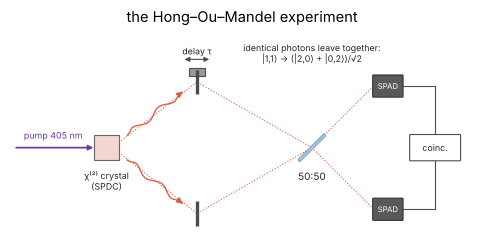

1 nm at 810 nm: 457 GHz, dip FWHM 1.37 ps = 409 µm of path


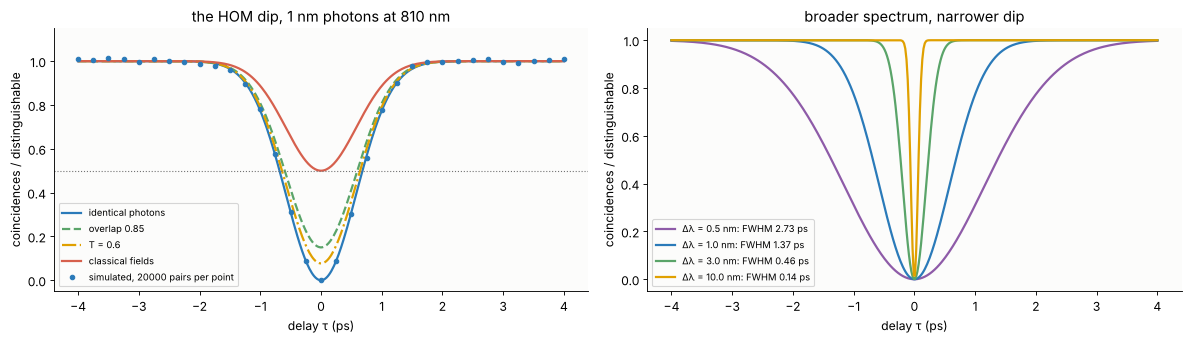

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.4))
sketch.detector_layout(ax, "hom", title="the Hong–Ou–Mandel experiment")
plt.show()
lam0, dlam = 810E-9, 1.0E-9
bw = 299792458.0*dlam/lam0**2
fwhm = d.hom_dip_fwhm(bw)
print("1 nm at 810 nm: {:.0f} GHz, dip FWHM {:.2f} ps = {:.0f} µm of path".format(bw/1E9, fwhm*1E12, fwhm*299792458.0*1E6))
tau = np.linspace(-4, 4, 400)*1E-12
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
ax.plot(tau*1E12, d.hom_coincidence(tau, bw), color=BLUE, lw=2, label="identical photons")
ax.plot(tau*1E12, d.hom_coincidence(tau, bw, overlap=0.85), color=GREEN, lw=2, ls="--", label="overlap 0.85")
ax.plot(tau*1E12, d.hom_coincidence(tau, bw, transmittance=0.6), color=ORANGE, lw=2, ls="-.", label="T = 0.6")
ax.plot(tau*1E12, d.hom_coincidence(tau, bw, classical=True), color=RED, lw=2, label="classical fields")
# counting experiment: 5000 pairs per point reach the detectors
taus = np.linspace(-4, 4, 33)*1E-12
pairs = 20000
cc = rng.binomial(pairs, 0.5*d.hom_coincidence(taus, bw))/(0.5*pairs)
ax.plot(taus*1E12, cc, "o", color=BLUE, ms=4, label=f"simulated, {pairs} pairs per point")
ax.axhline(0.5, color=GREY, ls=":", lw=1)
ax.set_xlabel("delay τ (ps)"); ax.set_ylabel("coincidences / distinguishable")
ax.set_title("the HOM dip, 1 nm photons at 810 nm"); ax.legend(fontsize=8.5); ax.set_ylim(-0.05, 1.15)
ax = axes[1]
dl = np.array([0.5, 1, 3, 10])*1E-9
for x, c in zip(dl, (PURPLE, BLUE, GREEN, ORANGE)):
    b = 299792458.0*x/lam0**2
    ax.plot(tau*1E12, d.hom_coincidence(tau, b), color=c, lw=2, label=f"Δλ = {x*1E9:.1f} nm: FWHM {d.hom_dip_fwhm(b)*1E12:.2f} ps")
ax.set_xlabel("delay τ (ps)"); ax.set_ylabel("coincidences / distinguishable")
ax.set_title("broader spectrum, narrower dip"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Photons of 1 nm bandwidth at 810 nm (457 GHz) give a dip 1.37 ps wide,
410 µm of path: the HOM interferometer measured sub-picosecond delays with
slow detectors, because the information is in *whether* coincidences
happen, not in when. The depth of the dip measures how identical the
photons are: an overlap of 0.85 leaves 15 % of the coincidences, and an
unbalanced splitter (T = 0.6) cannot reach zero either, since $T - R \ne 0$.
A dip deeper than 50 % rules out any classical explanation. The width is
the inverse of the bandwidth: 10 nm photons give a 0.14 ps dip.

The HOM effect is the elementary operation of linear optical quantum
computing and boson sampling, and the test of every single-photon source
for them: two photons from the same source, emitted one after the other,
must interfere with a visibility close to one.

## Summary

- The responsivity $\eta\lambda/1239.84$ nm A/W grows with the
  wavelength up to the band gap cutoff: 1.1 µm for Si, 1.7 µm for
  InGaAs, 5 or 12.5 µm for HgCdTe at 77 K depending on the cadmium
  fraction.
- The indirect gap of Si absorbs slowly (19 µm at 850 nm, 1 mm at
  1064 nm); direct gap materials absorb in micrometres. Thickness,
  dead layer and coating set the quantum efficiency.
- A photodiode's bandwidth is limited by $RC$ and by the transit time;
  smaller diodes are faster but absorb less (13 GHz and 62 % for a
  50 µm InGaAs diode).
- NEP and D* compare detectors. Visible and near-infrared diodes reach
  10¹³ Jones; infrared detectors are limited by the warm background
  (5×10¹⁰ Jones at 10 µm, more with a cold shield). Infrared detectors are
  detector limited at any realistic power, the origin of the Fellgett
  advantage.
- SPADs count single photons, but a dead time saturates them and makes
  the counts look sub-Poissonian.
- Coherent light is Poissonian, thermal light super-Poissonian, number
  states sub-Poissonian; losses push all towards Poisson.
- With vacuum at the second port a beam splitter splits every light
  binomially, so HBT measures $g^{(2)}$: 1, 2 and 0 for a laser, thermal
  light and single photons. Two identical photons at a 50:50 splitter
  leave together: the HOM dip, as wide as the photons' coherence time.

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 5 s


## References

- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), chapters 13 and 19.
- A. Rogalski, *Infrared and Terahertz Detectors*, 3rd ed., CRC Press
  (2019).
- M. A. Green, "Self-consistent optical parameters of intrinsic silicon at
  300 K including temperature coefficients", Sol. Energy Mater. Sol.
  Cells 92, 1305–1310 (2008).
- G. L. Hansen, J. L. Schmit and T. N. Casselman, "Energy gap versus alloy
  composition and temperature in Hg₁₋ₓCdₓTe", J. Appl. Phys. 53,
  7099–7101 (1982).
- J. Chu, B. Li, K. Liu and D. Tang, "Empirical rule of intrinsic
  absorption spectroscopy in Hg₁₋ₓCdₓTe", J. Appl. Phys. 75, 1234–1235
  (1994).
- R. Loudon, *The Quantum Theory of Light*, 3rd ed., Oxford University
  Press (2000), chapters 5 and 6.
- L. Mandel and E. Wolf, *Optical Coherence and Quantum Optics*,
  Cambridge University Press (1995), chapter 9.
- P. Grangier, G. Roger and A. Aspect, "Experimental evidence for a
  photon anticorrelation effect on a beam splitter", Europhys. Lett. 1,
  173–179 (1986).
- C. K. Hong, Z. Y. Ou and L. Mandel, "Measurement of subpicosecond time
  intervals between two photons by interference", Phys. Rev. Lett. 59,
  2044–2046 (1987).
- G. P. Agrawal, *Fiber-Optic Communication Systems*, 4th ed., Wiley
  (2010), chapter 4.